# Cross-Domain Generalization and Lightweight Domain Adaptation for SMS Spam Detection

**Research question.** Does an SMS spam classifier trained on one dataset (UCI SMS Spam Collection,
UK messages) still work on an independently collected dataset (Indian SMS), and does adding a small
number of labelled Indian messages to training help?

| Name | Role |
|---|---|
| Dataset A: UCI SMS Spam Collection | Source domain: the model learns here |
| Dataset B: India Spam SMS Classification | Target domain: the model is tested here |

The notebook follows the guide's stages in order. Every number printed below is produced by the code
in this notebook; nothing is typed by hand.

**Run it in Google Colab:** Runtime → Run all. It downloads both datasets itself.

## 0. Setup
Fixed seeds make every run give the same numbers. `SEEDS` are the three repetitions the guide asks for.

In [1]:
import os, io, re, json, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from scipy.stats import binomtest
from sklearn.metrics import f1_score as _f1  # noqa: F401
import joblib

try:
    import ftfy  # repairs text whose encoding was broken (mojibake)
except ImportError:
    os.system("pip -q install ftfy")
    import ftfy

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

MAIN_SEED = 42            # the guide's random_state
SEEDS = [42, 123, 2026]   # three repetitions for mean ± standard deviation
ADAPT_FRACTIONS = [0.0, 0.10, 0.20, 0.40]   # share of the target adaptation pool added to training
REFERENCE_FRACTION = 1.0  # extra reference row: the whole pool (not part of the guide's protocol)

DATA_DIR = "data/raw"
OUT = "outputs"
for d in (DATA_DIR, OUT, f"{OUT}/figures", f"{OUT}/tables", f"{OUT}/models", "data/clean"):
    os.makedirs(d, exist_ok=True)

UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
INDIA_URL = ("https://raw.githubusercontent.com/junioralive/india-spam-sms-classification/"
             "main/dataset/spam_ham_india.csv")

print("Python libraries:", "pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python libraries: pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.7.2 | matplotlib 3.11.2


## 1. Load both datasets (guide Prompt 2)
If the files are already in `data/raw` they are used; otherwise they are downloaded from the
official UCI page and the dataset's GitHub repository.

In [2]:
uci_path = os.path.join(DATA_DIR, "SMSSpamCollection")
if not os.path.exists(uci_path):
    raw = urllib.request.urlopen(UCI_URL).read()
    zipfile.ZipFile(io.BytesIO(raw)).extract("SMSSpamCollection", DATA_DIR)

india_path = os.path.join(DATA_DIR, "spam_ham_india.csv")
if not os.path.exists(india_path):
    urllib.request.urlretrieve(INDIA_URL, india_path)

# UCI: tab-separated, no header, columns = label, message. quoting=3 keeps quote characters as text.
A_raw = pd.read_csv(uci_path, sep="\t", header=None, names=["label", "message"], quoting=3)
# India: CSV with columns Msg, Label (checked by reading the file, not assumed)
B_raw = pd.read_csv(india_path, encoding="utf-8")
print("Dataset B columns found:", B_raw.columns.tolist())
B_raw = B_raw.rename(columns={"Msg": "message", "Label": "label"})

print("\nDataset A, first 10 records")
display(A_raw.head(10)) if "display" in globals() else print(A_raw.head(10))
print("\nDataset B, first 10 records")
display(B_raw.head(10)) if "display" in globals() else print(B_raw.head(10))

Dataset B columns found: ['Msg', 'Label']

Dataset A, first 10 records
  label  \
0   ham   
1   ham   
2  spam   
3   ham   
4   ham   
5  spam   
6   ham   
7   ham   
8  spam   
9  spam   

                                                                                                                   message  
0          Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...  
1                                                                                            Ok lar... Joking wif u oni...  
2  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...  
3                                                                        U dun say so early hor... U c already then say...  
4                                                            Nah I don't think he goes to usf, he lives around here though  
5  FreeMsg Hey there darling it's been 3 week's now and n

## 2. Audit both datasets
Checks from the guide's audit checklist: size, classes, missing values, duplicates, message
length, label conflicts, broken text, and provenance.

In [3]:
def audit(df, name):
    msg = df["message"].astype(str)
    return {
        "dataset": name,
        "total_rows": len(df),
        "ham": int((df["label"].astype(str).str.strip().str.lower() == "ham").sum()),
        "spam": int((df["label"].astype(str).str.strip().str.lower() == "spam").sum()),
        "missing_message": int(df["message"].isna().sum()),
        "missing_label": int(df["label"].isna().sum()),
        "exact_duplicate_messages": int(df["message"].duplicated().sum()),
        "duplicates_with_conflicting_labels": int(df.dropna().groupby("message")["label"].nunique().gt(1).sum()),
        "broken_encoding_rows": int(msg.str.contains(r"Ã|â€|Â").sum()),
        "rows_with_lost_characters_????": int(msg.str.contains(r"\?{4,}").sum()),
        "median_length_chars": float(msg.str.len().median()),
    }

audit_table = pd.DataFrame([audit(A_raw, "A: UCI SMS Spam Collection"), audit(B_raw, "B: India Spam SMS")])
audit_table.to_csv(f"{OUT}/tables/table0_raw_audit.csv", index=False)
audit_table.T

,0,1
dataset,A: UCI SMS Spam Collection,B: India Spam SMS
total_rows,5574,2267
ham,4827,1522
spam,747,745
missing_message,0,1
missing_label,0,0
exact_duplicate_messages,403,204
duplicates_with_conflicting_labels,0,0
broken_encoding_rows,0,176
rows_with_lost_characters_????,5,40


**Provenance (checked on the source pages)**

| | Dataset A | Dataset B |
|---|---|---|
| Source | UCI Machine Learning Repository, Almeida, Gómez Hidalgo & Yamakami (2011) | GitHub `junioralive/india-spam-sms-classification` (also on Kaggle) |
| Licence | CC BY 4.0 | MIT (2024) |
| How it was collected | Documented in the 2011 paper (UK forum, NUS corpus, Caroline Tag's thesis, Grumbletext) | Crowd-sourced through a Google Form; no written labelling procedure |
| Label meaning | spam = unsolicited commercial or fraudulent SMS | spam / ham, not defined further |

Because Dataset B has no documented labelling procedure, the label spot-check below is required
before using it as a target domain.

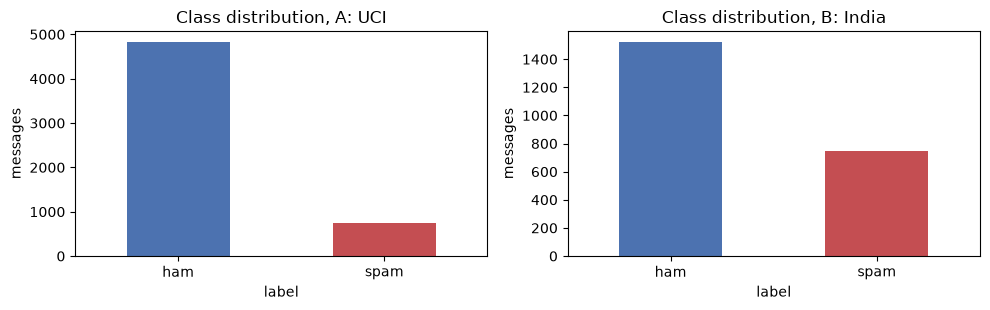

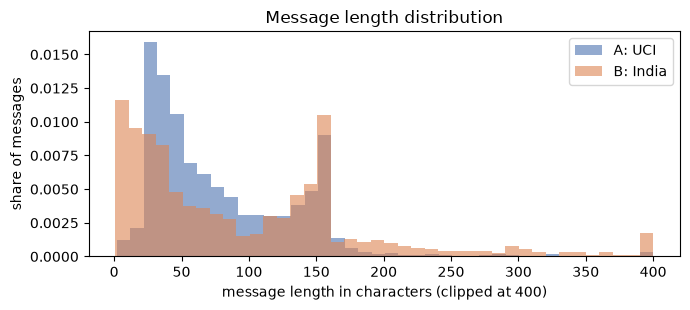

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, df) in zip(axes, [("A: UCI", A_raw), ("B: India", B_raw)]):
    df["label"].value_counts().reindex(["ham", "spam"]).plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
    ax.set_title(f"Class distribution, {name}"); ax.set_ylabel("messages"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig1_class_distribution.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2))
for name, df, c in [("A: UCI", A_raw, "#4C72B0"), ("B: India", B_raw, "#DD8452")]:
    ax.hist(df["message"].astype(str).str.len().clip(upper=400), bins=40, alpha=0.6, label=name, color=c, density=True)
ax.set_xlabel("message length in characters (clipped at 400)"); ax.set_ylabel("share of messages"); ax.legend()
ax.set_title("Message length distribution")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig2_length_distribution.png", dpi=200); plt.show()

**Label spot-check.** Ten random messages of each class from Dataset B, to judge whether the labels
are plausible (the guide asks for this before Dataset B is used).

In [5]:
for lab in ["spam", "ham"]:
    print(f"--- Dataset B, label = {lab} ---")
    for t in B_raw[B_raw["label"] == lab]["message"].dropna().sample(10, random_state=MAIN_SEED):
        print("  •", ftfy.fix_text(str(t))[:150])

--- Dataset B, label = spam ---
  • Dear Customer, Rs.500 to 10 lucky winners & Rs.50 to 1,000 Early Birds as STAR Clubcard points! To share your feedback, click https://bit.ly/3QfJ07p T
  • Its MY SALE MY WAY at shoppersstop.com Enjoy upto 50% OFF + Use Code AC2K & get Rs.250 off on Rs.2500 & Rs.500 off on Rs.4000 Click bit.ly/SS_ESS to s
  • Watch the India vs Srilanka series LIVE on Sonyliv with Airtel Xstream Play. Click to watch - open.airtelxstream.in/Cheer_for_India
  • Yay, Reward unlocked! Enjoy a FREE small scoop on your next visit to Baskin Robbins! Hurry, this offer ends in 45 days! T&C Apply
  • Cloudnine administrator has assigned 6 course(s) to you. These courses need to be completed by 18-12-2021 . Please click on the link to start your tra
  • Hello Your Unlimited pack MRP is expiring on2021-08-06 00:00:00.Now recharge from home with App Click http://bit.ly/GetMVA4
  • Mic Drop Offer- only for 24 hours! Wynk Premium now @Rs 299 for 12 months. Get unlimited downloads, H

## 3. Cleaning and preprocessing (guide Prompt 3)

The same steps are applied to both datasets, in this order. Each step's row count is recorded.

1. Map labels to spam = 1, ham = 0 and drop rows with a missing message or an invalid label.
2. Repair broken encoding with `ftfy` (Dataset B stores emoji and apostrophes as garbage such as
   `Ã°Â\x9fÂ\x91Â\x8d`). Repairing is better than deleting, because the rest of the message is fine.
3. Lowercase, strip leading/trailing spaces, collapse repeated whitespace.
4. Remove exact duplicates inside each dataset (keep the first copy).
5. Remove from Dataset B any message that also appears in Dataset A.

URLs, numbers and punctuation are **kept**: they are strong spam signals ("Click bit.ly/...", "Rs.5000").

In [6]:
LABEL_MAP = {"spam": 1, "ham": 0}

def clean_dataset(df, name, log):
    d = df.copy()
    log.append((name, "raw rows", len(d)))
    d["label"] = d["label"].astype(str).str.strip().str.lower().map(LABEL_MAP)
    d = d.dropna(subset=["message", "label"])
    d = d[d["message"].astype(str).str.strip() != ""]
    log.append((name, "after removing missing or invalid rows", len(d)))
    d["message"] = d["message"].astype(str).map(ftfy.fix_text)
    d["message"] = d["message"].str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
    d = d[d["message"] != ""]
    d["label"] = d["label"].astype(int)
    before = len(d)
    d = d.drop_duplicates(subset="message", keep="first")
    log.append((name, f"after removing {before - len(d)} exact duplicates", len(d)))
    return d.reset_index(drop=True)

clean_log = []
A = clean_dataset(A_raw, "A", clean_log)
B = clean_dataset(B_raw, "B", clean_log)

cross = B["message"].isin(set(A["message"]))
print("Messages present in both datasets:", B.loc[cross, "message"].tolist())
B = B[~cross].reset_index(drop=True)
clean_log.append(("B", f"after removing {int(cross.sum())} message(s) also in A", len(B)))

conflicts = {n: int(df.groupby("message")["label"].nunique().gt(1).sum()) for n, df in [("A", A), ("B", B)]}
print("Messages with two different labels after cleaning:", conflicts)

steps = pd.DataFrame(clean_log, columns=["dataset", "step", "rows"])
steps.to_csv(f"{OUT}/tables/table1a_cleaning_steps.csv", index=False)
display(steps) if "display" in globals() else print(steps)

A["domain"], B["domain"] = "UCI", "India"
A.to_csv("data/clean/dataset_A_uci_clean.csv", index=False)
B.to_csv("data/clean/dataset_B_india_clean.csv", index=False)

Messages present in both datasets: ['ok']
Messages with two different labels after cleaning: {'A': 0, 'B': 0}
  dataset                                    step  rows
0       A                                raw rows  5574
1       A  after removing missing or invalid rows  5574
2       A     after removing 416 exact duplicates  5158
3       B                                raw rows  2267
4       B  after removing missing or invalid rows  2266
5       B     after removing 215 exact duplicates  2051
6       B   after removing 1 message(s) also in A  2050


In [7]:
def stats_row(raw, clean, name, provenance):
    return {"Dataset": name, "Total rows (raw)": len(raw), "Rows after cleaning": len(clean),
            "Ham": int((clean.label == 0).sum()), "Spam": int((clean.label == 1).sum()),
            "Spam share": f"{(clean.label == 1).mean():.1%}",
            "Missing removed": int(raw["message"].isna().sum()),
            "Duplicates removed": len(raw) - int(raw["message"].isna().sum()) - len(clean),
            "Notes / provenance": provenance}

table1 = pd.DataFrame([
    stats_row(A_raw, A, "UCI SMS Spam", "UCI repository, CC BY 4.0"),
    stats_row(B_raw, B, "Indian SMS candidate", "GitHub junioralive, MIT; crowd-sourced; 1 message shared with A removed"),
])
table1.to_csv(f"{OUT}/tables/table1_dataset_statistics.csv", index=False)
table1

,Dataset,Total rows (raw),Rows after cleaning,Ham,Spam,Spam share,Missing removed,Duplicates removed,Notes / provenance
0,UCI SMS Spam,5574,5158,4517,641,12.4%,0,416,"UCI repository, CC BY 4.0"
1,Indian SMS candidate,2267,2050,1314,736,35.9%,1,216,"GitHub junioralive, MIT; crowd-sourced; 1 message shared with A removed"


## 4. TF-IDF feature extraction (guide Prompt 4)

TF-IDF turns each message into a vector of numbers. Each **row** is one message, each **column** is
one word (or character piece), and the value is high when that piece is frequent in this message
but rare across the training messages.

* **Word TF-IDF:** unigrams and bigrams, at most 20,000 features (as the guide specifies).
* **Character TF-IDF:** `char_wb`, 3- to 5-character pieces inside word boundaries. It can still
  match "fr33" to "free" through shared pieces like "fr", and "offr" to "offer".

**No leakage:** a vectorizer is always fitted on training data only and then used to transform test
data. Here we only show the matrix sizes; the models are built in the next section.

In [8]:
FEATURES = {
    "word": dict(analyzer="word", ngram_range=(1, 2), max_features=20000),
    "char": dict(analyzer="char_wb", ngram_range=(3, 5)),
}
with open(f"{OUT}/feature_config.json", "w") as fh:
    json.dump({k: {**v, "ngram_range": list(v["ngram_range"])} for k, v in FEATURES.items()}, fh, indent=1)

A_tr, A_te = train_test_split(A, test_size=0.20, stratify=A["label"], random_state=MAIN_SEED)
for name, cfg in FEATURES.items():
    vec = TfidfVectorizer(**cfg).fit(A_tr["message"])          # fitted on Dataset A training data only
    X_tr, X_te, X_B = vec.transform(A_tr["message"]), vec.transform(A_te["message"]), vec.transform(B["message"])
    print(f"{name:5s} TF-IDF  A-train {X_tr.shape}  A-test {X_te.shape}  B {X_B.shape}  "
          f"(rows = messages, columns = features)")

word  TF-IDF  A-train (4126, 20000)  A-test (1032, 20000)  B (2050, 20000)  (rows = messages, columns = features)


char  TF-IDF  A-train (4126, 67027)  A-test (1032, 67027)  B (2050, 67027)  (rows = messages, columns = features)


## 5. Baseline models on Dataset A (guide Prompt 5)

* **Multinomial Naive Bayes:** counts how often each feature appears in spam and in ham and applies Bayes' rule.
* **Logistic Regression:** learns one weight per feature; `class_weight="balanced"` because only 13% of
  Dataset A is spam, so errors on spam would otherwise count too little.
* **Linear SVM:** optional comparison, as the guide allows.

Spam = 1 is the positive class. Split: 80% train / 20% test, stratified, random_state = 42.

In [9]:
BEST = {}   # hyperparameters chosen on Dataset A training data only (filled in below)

def make_model(model, params=None):
    params = params or {}
    if model == "naive_bayes":
        return MultinomialNB(**params)
    if model == "logistic_regression":
        return LogisticRegression(max_iter=1000, class_weight="balanced", **params)
    if model == "linear_svm":
        return LinearSVC(class_weight="balanced", **params)
    raise ValueError(model)

def make_pipeline(model, feature, params=None):
    if params is None:
        params = BEST.get((model, feature), {})
    return Pipeline([("tfidf", TfidfVectorizer(**FEATURES[feature])), ("clf", make_model(model, params))])

def scores(y, yhat):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0), "f1": f1_score(y, yhat, zero_division=0),
            "macro_f1": f1_score(y, yhat, average="macro", zero_division=0),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

MODELS = ["naive_bayes", "logistic_regression", "linear_svm"]
NICE = {"naive_bayes": "Naive Bayes", "logistic_regression": "Logistic Regression", "linear_svm": "Linear SVM"}

### 5a. Choosing hyperparameters fairly
Each model has one setting that matters: the smoothing `alpha` of Naive Bayes and the regularisation
strength `C` of Logistic Regression and the SVM. We choose it by **5-fold cross-validation on Dataset A
training data only** (spam F1). Dataset B is never looked at, as the guide requires. The chosen values
are then fixed for every experiment and every seed.

In [10]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
GRID = {"naive_bayes": {"clf__alpha": [1.0, 0.3, 0.1, 0.03, 0.01]},
        "logistic_regression": {"clf__C": [0.1, 1, 10, 100]},
        "linear_svm": {"clf__C": [0.01, 0.1, 1, 10]}}
cv_rows = []
for model in MODELS:
    for feature in FEATURES:
        g = GridSearchCV(make_pipeline(model, feature, params={}), GRID[model], scoring="f1",
                         cv=StratifiedKFold(5, shuffle=True, random_state=MAIN_SEED)).fit(A_tr["message"], A_tr["label"])
        BEST[(model, feature)] = {k.replace("clf__", ""): v for k, v in g.best_params_.items()}
        cv_rows.append({"model": NICE[model], "feature": feature, "chosen": BEST[(model, feature)], "CV spam F1 on A-train": round(g.best_score_, 4)})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(f"{OUT}/tables/table_hyperparameters.csv", index=False)
cv_table

,model,feature,chosen,CV spam F1 on A-train
0,Naive Bayes,word,{'alpha': 0.03},0.9441
1,Naive Bayes,char,{'alpha': 0.03},0.9513
2,Logistic Regression,word,{'C': 100},0.9391
3,Logistic Regression,char,{'C': 10},0.9642
4,Linear SVM,word,{'C': 1},0.9464
5,Linear SVM,char,{'C': 1},0.9641


For comparison, Naive Bayes with the library default (`alpha = 1.0`). With TF-IDF features and only
12% spam in Dataset A, the default smoothing makes Naive Bayes predict "ham" for almost everything.

In [11]:
nb_default = make_pipeline("naive_bayes", "word", params={"alpha": 1.0}).fit(A_tr["message"], A_tr["label"])
nb_default_row = {"setting": "Naive Bayes, default alpha = 1.0, word TF-IDF",
                  "A-test F1": f1_score(A_te["label"], nb_default.predict(A_te["message"])),
                  "B F1": f1_score(B["label"], nb_default.predict(B["message"]))}
pd.DataFrame([nb_default_row]).to_csv(f"{OUT}/tables/table_nb_default_alpha.csv", index=False)
pd.DataFrame([nb_default_row]).round(4)

,setting,A-test F1,B F1
0,"Naive Bayes, default alpha = 1.0, word TF-IDF",0.7264,0.0135


### 5b. Baseline results with the chosen settings

In [12]:

source_models, rows = {}, []
for model in MODELS:
    pipe = make_pipeline(model, "word").fit(A_tr["message"], A_tr["label"])
    source_models[(model, "word")] = pipe
    s = scores(A_te["label"], pipe.predict(A_te["message"]))
    rows.append({"Model": NICE[model], "Feature": "Word TF-IDF", "Test domain": "Source A", **s})
    print(f"\n{NICE[model]} on Dataset A test (word TF-IDF)")
    print(classification_report(A_te["label"], pipe.predict(A_te["message"]), target_names=["ham", "spam"], digits=4))
baseline = pd.DataFrame(rows)
baseline.round(4)


Naive Bayes on Dataset A test (word TF-IDF)
              precision    recall  f1-score   support

         ham     0.9814    0.9934    0.9874       904
        spam     0.9487    0.8672    0.9061       128

    accuracy                         0.9777      1032
   macro avg     0.9651    0.9303    0.9467      1032
weighted avg     0.9774    0.9777    0.9773      1032




Logistic Regression on Dataset A test (word TF-IDF)
              precision    recall  f1-score   support

         ham     0.9836    0.9923    0.9879       904
        spam     0.9417    0.8828    0.9113       128

    accuracy                         0.9787      1032
   macro avg     0.9626    0.9375    0.9496      1032
weighted avg     0.9784    0.9787    0.9784      1032




Linear SVM on Dataset A test (word TF-IDF)
              precision    recall  f1-score   support

         ham     0.9815    0.9956    0.9885       904
        spam     0.9652    0.8672    0.9136       128

    accuracy                         0.9797      1032
   macro avg     0.9733    0.9314    0.9510      1032
weighted avg     0.9794    0.9797    0.9792      1032



,Model,Feature,Test domain,accuracy,precision,recall,f1,macro_f1,TN,FP,FN,TP
0,Naive Bayes,Word TF-IDF,Source A,0.9777,0.9487,0.8672,0.9061,0.9467,898,6,17,111
1,Logistic Regression,Word TF-IDF,Source A,0.9787,0.9417,0.8828,0.9113,0.9496,897,7,15,113
2,Linear SVM,Word TF-IDF,Source A,0.9797,0.9652,0.8672,0.9136,0.9510,900,4,17,111


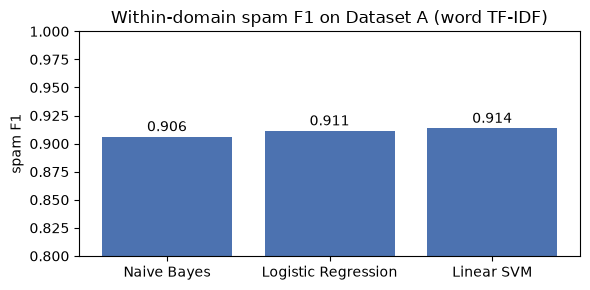

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(baseline["Model"], baseline["f1"], color="#4C72B0")
for i, v in enumerate(baseline["f1"]):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
ax.set_ylim(0.8, 1.0); ax.set_ylabel("spam F1"); ax.set_title("Within-domain spam F1 on Dataset A (word TF-IDF)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig3_baseline_f1.png", dpi=200); plt.show()

## 6. Main experiment: cross-domain generalization (guide Prompt 6)

The models trained above (Dataset A training data only, vectorizer fitted on A only) are applied
**without any retraining** to all of Dataset B. The drop from source F1 to target F1 is the
cross-domain gap.

In [14]:
rows = []
for feature in FEATURES:
    for model in MODELS:
        pipe = source_models.get((model, feature)) or make_pipeline(model, feature).fit(A_tr["message"], A_tr["label"])
        source_models[(model, feature)] = pipe
        sA = scores(A_te["label"], pipe.predict(A_te["message"]))
        sB = scores(B["label"], pipe.predict(B["message"]))
        rows.append({"Model": NICE[model], "Feature": feature, "Source A F1": sA["f1"], "Target B F1": sB["f1"],
                     "F1 gap (A - B)": sA["f1"] - sB["f1"], "Target accuracy": sB["accuracy"],
                     "Target precision": sB["precision"], "Target recall": sB["recall"],
                     "Target TN": sB["TN"], "Target FP": sB["FP"], "Target FN": sB["FN"], "Target TP": sB["TP"]})
cross_domain = pd.DataFrame(rows)
cross_domain.to_csv(f"{OUT}/tables/table2b_cross_domain_full_B.csv", index=False)
cross_domain.round(4)

,Model,Feature,Source A F1,Target B F1,F1 gap (A - B),Target accuracy,Target precision,Target recall,Target TN,Target FP,Target FN,Target TP
0,Naive Bayes,word,0.9061,0.5514,0.3547,0.7659,0.8832,0.4008,1275,39,441,295
1,Logistic Regression,word,0.9113,0.6776,0.2337,0.8180,0.9311,0.5326,1285,29,344,392
2,Linear SVM,word,0.9136,0.6152,0.2983,0.7956,0.9490,0.4552,1296,18,401,335
3,Naive Bayes,char,0.9478,0.6842,0.2636,0.8180,0.9079,0.5489,1273,41,332,404
4,Logistic Regression,char,0.9398,0.6379,0.3018,0.8034,0.9416,0.4823,1292,22,381,355
5,Linear SVM,char,0.9431,0.5782,0.3649,0.7829,0.9561,0.4144,1300,14,431,305


In [15]:
# Table 2 in the guide's format (word TF-IDF, NB and LR, source test and all of Dataset B)
t2 = []
for model in ["naive_bayes", "logistic_regression"]:
    pipe = source_models[(model, "word")]
    for dom, X, y in [("Source A", A_te["message"], A_te["label"]), ("Target B", B["message"], B["label"])]:
        s = scores(y, pipe.predict(X))
        t2.append({"Model": NICE[model], "Feature": "Word TF-IDF", "Test domain": dom,
                   "Accuracy": s["accuracy"], "Precision": s["precision"], "Recall": s["recall"], "F1-score": s["f1"]})
table2 = pd.DataFrame(t2)
table2.to_csv(f"{OUT}/tables/table2_within_vs_cross_domain.csv", index=False)
table2.round(4)

,Model,Feature,Test domain,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,Word TF-IDF,Source A,0.9777,0.9487,0.8672,0.9061
1,Naive Bayes,Word TF-IDF,Target B,0.7659,0.8832,0.4008,0.5514
2,Logistic Regression,Word TF-IDF,Source A,0.9787,0.9417,0.8828,0.9113
3,Logistic Regression,Word TF-IDF,Target B,0.8180,0.9311,0.5326,0.6776


## 7. Why the domains differ: vocabulary and message characteristics
Objective 3 of the guide. We measure how much of Dataset B's vocabulary was ever seen in Dataset A
training data, and compare simple message characteristics.

In [16]:
tok = TfidfVectorizer(analyzer="word").build_analyzer()
vocab_A = set(w for t in A_tr["message"] for w in tok(t))

def oov_rate(text):
    words = tok(text)
    return np.mean([w not in vocab_A for w in words]) if words else np.nan

def characteristics(df, name):
    m = df["message"]
    return {"Domain": name, "Messages": len(df), "Median length (chars)": m.str.len().median(),
            "Has URL": m.str.contains(r"https?://|www\.|bit\.ly|\b\w+\.(?:com|in|ly|me)\b").mean(),
            "Has a number": m.str.contains(r"\d").mean(),
            "Has currency (rs/inr/₹/£)": m.str.contains(r"\brs\.?\b|\binr\b|₹|£").mean(),
            "Mean share of words unseen in A-train": m.map(oov_rate).mean()}

char_tab = pd.DataFrame([characteristics(A_te, "A test (UCI)"), characteristics(B, "B (India)"),
                         characteristics(B[B.label == 1], "B spam"), characteristics(B[B.label == 0], "B ham")])
char_tab.to_csv(f"{OUT}/tables/table7_domain_characteristics.csv", index=False)
vocab_B = set(w for t in B["message"] for w in tok(t))
print(f"Distinct words: A-train {len(vocab_A):,}, B {len(vocab_B):,}; "
      f"{len(vocab_B - vocab_A) / len(vocab_B):.1%} of B's distinct words never occur in A-train")
char_tab.round(3)

Distinct words: A-train 7,639, B 4,942; 62.5% of B's distinct words never occur in A-train


,Domain,Messages,Median length (chars),Has URL,Has a number,Has currency (rs/inr/₹/£),Mean share of words unseen in A-train
0,A test (UCI),1032,59.0,0.016,0.242,0.038,0.078
1,B (India),2050,81.0,0.312,0.423,0.090,0.207
2,B spam,736,153.0,0.870,0.921,0.243,0.271
3,B ham,1314,39.0,0.000,0.144,0.004,0.170


## 8. Lightweight supervised domain adaptation (guide Prompt 7)

For each seed:
1. Split Dataset A 80/20 and Dataset B 70/30 (adaptation pool / final target test), both stratified.
2. Take 0%, 10%, 20% and 40% of the adaptation pool (stratified sample).
3. Training data = Dataset A train + that sample. **Refit TF-IDF and the classifier on it.**
4. Evaluate on the same untouched final target test set.

0% is the source-only model. The final target test set is never used for training, fitting the
vectorizer or choosing anything. A 100% row is added only as a reference for the upper end.

In [17]:
def run_seed(seed, fractions, models=("naive_bayes", "logistic_regression"), features=("word", "char")):
    a_tr, a_te = train_test_split(A, test_size=0.20, stratify=A["label"], random_state=seed)
    pool, b_te = train_test_split(B, test_size=0.30, stratify=B["label"], random_state=seed)
    out, preds = [], {}
    for frac in fractions:
        if frac == 0:
            add = pool.iloc[0:0]
        elif frac >= 1:
            add = pool
        else:
            add, _ = train_test_split(pool, train_size=frac, stratify=pool["label"], random_state=seed)
        train = pd.concat([a_tr, add])
        for model in models:
            for feature in features:
                pipe = make_pipeline(model, feature).fit(train["message"], train["label"])
                yb = pipe.predict(b_te["message"])
                sB = scores(b_te["label"], yb)
                sA = scores(a_te["label"], pipe.predict(a_te["message"]))
                preds[(model, feature, frac)] = yb
                out.append({"seed": seed, "model": model, "feature": feature, "target_fraction": frac,
                            "target_messages_added": len(add), "train_size": len(train),
                            **{f"B_{k}": v for k, v in sB.items()}, "A_f1": sA["f1"]})
    return pd.DataFrame(out), preds, b_te

all_runs, seed_preds, seed_tests = [], {}, {}
for seed in SEEDS:
    df_seed, preds, b_te = run_seed(seed, ADAPT_FRACTIONS + [REFERENCE_FRACTION])
    all_runs.append(df_seed); seed_preds[seed] = preds; seed_tests[seed] = b_te
    print(f"seed {seed}: pool {len(B) - len(b_te)} messages, final target test {len(b_te)} messages")
runs = pd.concat(all_runs, ignore_index=True)
runs.to_csv(f"{OUT}/tables/all_runs_per_seed.csv", index=False)

seed 42: pool 1435 messages, final target test 615 messages


seed 123: pool 1435 messages, final target test 615 messages


seed 2026: pool 1435 messages, final target test 615 messages


In [18]:
def mean_sd(df, keys, cols):
    g = df.groupby(keys)[cols].agg(["mean", "std"])
    g.columns = [f"{c}_{s}" for c, s in g.columns]
    return g.reset_index()

summary = mean_sd(runs, ["model", "feature", "target_fraction"], ["B_accuracy", "B_precision", "B_recall", "B_f1", "A_f1"])
summary.to_csv(f"{OUT}/tables/summary_mean_sd.csv", index=False)

def fmt(m, s):
    return f"{m:.4f} ± {s:.4f}"

t3 = []
for model in ["naive_bayes", "logistic_regression"]:
    for frac in ADAPT_FRACTIONS + [REFERENCE_FRACTION]:
        r = summary[(summary.model == model) & (summary.feature == "word") & (summary.target_fraction == frac)].iloc[0]
        label = "0% (source-only)" if frac == 0 else ("100% (reference)" if frac >= 1 else f"{int(frac * 100)}%")
        t3.append({"Model": NICE[model], "Target adaptation data": label,
                   "Accuracy": fmt(r.B_accuracy_mean, r.B_accuracy_std), "Precision": fmt(r.B_precision_mean, r.B_precision_std),
                   "Recall": fmt(r.B_recall_mean, r.B_recall_std), "F1-score": fmt(r.B_f1_mean, r.B_f1_std),
                   "Source A F1": fmt(r.A_f1_mean, r.A_f1_std)})
table3 = pd.DataFrame(t3)
table3.to_csv(f"{OUT}/tables/table3_domain_adaptation_word.csv", index=False)
print("Table 3 (word TF-IDF), mean ± SD over seeds", SEEDS)
table3

Table 3 (word TF-IDF), mean ± SD over seeds [42, 123, 2026]


,Model,Target adaptation data,Accuracy,Precision,Recall,F1-score,Source A F1
0,Naive Bayes,0% (source-only),0.7778 ± 0.0066,0.8990 ± 0.0042,0.4299 ± 0.0197,0.5815 ± 0.0182,0.9266 ± 0.0206
1,Naive Bayes,10%,0.9642 ± 0.0043,0.9585 ± 0.0047,0.9412 ± 0.0078,0.9498 ± 0.0061,0.9298 ± 0.0161
2,Naive Bayes,20%,0.9762 ± 0.0050,0.9654 ± 0.0067,0.9683 ± 0.0120,0.9669 ± 0.0070,0.9300 ± 0.0161
3,Naive Bayes,40%,0.9843 ± 0.0066,0.9745 ± 0.0070,0.9819 ± 0.0120,0.9782 ± 0.0092,0.9301 ± 0.0221
4,Naive Bayes,100% (reference),0.9908 ± 0.0047,0.9850 ± 0.0102,0.9894 ± 0.0026,0.9872 ± 0.0065,0.9186 ± 0.0222
5,Logistic Regression,0% (source-only),0.8201 ± 0.0092,0.9372 ± 0.0112,0.5354 ± 0.0346,0.6809 ± 0.0254,0.9279 ± 0.0145
6,Logistic Regression,10%,0.9740 ± 0.0028,0.9653 ± 0.0065,0.9623 ± 0.0094,0.9637 ± 0.0040,0.9278 ± 0.0231
7,Logistic Regression,20%,0.9767 ± 0.0034,0.9614 ± 0.0088,0.9744 ± 0.0052,0.9678 ± 0.0046,0.9255 ± 0.0212
8,Logistic Regression,40%,0.9816 ± 0.0034,0.9702 ± 0.0108,0.9789 ± 0.0069,0.9745 ± 0.0046,0.9270 ± 0.0207
9,Logistic Regression,100% (reference),0.9908 ± 0.0025,0.9807 ± 0.0051,0.9940 ± 0.0026,0.9873 ± 0.0034,0.9210 ± 0.0270


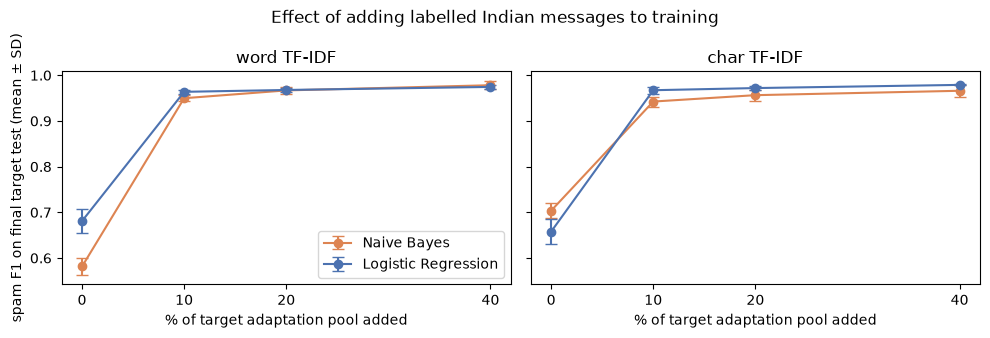

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, feature in zip(axes, ["word", "char"]):
    for model, c in [("naive_bayes", "#DD8452"), ("logistic_regression", "#4C72B0")]:
        r = summary[(summary.model == model) & (summary.feature == feature) & (summary.target_fraction < 1)]
        ax.errorbar(r.target_fraction * 100, r.B_f1_mean, yerr=r.B_f1_std, marker="o", capsize=4, color=c, label=NICE[model])
    ax.set_title(f"{feature} TF-IDF"); ax.set_xlabel("% of target adaptation pool added"); ax.set_xticks([0, 10, 20, 40])
axes[0].set_ylabel("spam F1 on final target test (mean ± SD)"); axes[0].legend()
plt.suptitle("Effect of adding labelled Indian messages to training")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig4_adaptation_curve.png", dpi=200); plt.show()

## 8b. Robustness check: are near-copies inflating the adaptation gain?

Indian promotional SMS are sent from templates ("Get 5GB free data... click ..."). With a random 70/30
split, a near-copy of a test message can sit in the adaptation pool, and the model then "recognises"
the template instead of generalising. We group near-duplicates with **MinHash** (estimated Jaccard
similarity ≥ 0.6 on word 3-shingles, after replacing links and digits) and repeat the adaptation
experiment with a **group-aware split**: every near-duplicate group goes wholly to the pool or wholly
to the test set.

In [20]:
try:
    from datasketch import MinHash, MinHashLSH
except ImportError:
    os.system("pip -q install datasketch")
    from datasketch import MinHash, MinHashLSH
from sklearn.model_selection import GroupShuffleSplit

def shingle_words(t):
    t = re.sub(r"https?://\S+|\S+\.(com|in|ly|me)\S*", " url ", t)
    t = re.sub(r"\d+", "0", t)
    return re.sub(r"[^a-z0 ]+", " ", t).split()

lsh, groups, first = MinHashLSH(threshold=0.6, num_perm=96), [], {}
for i, t in enumerate(B["message"]):
    w = shingle_words(t)
    h = MinHash(num_perm=96)
    for sh in {" ".join(w[j:j + 3]) for j in range(max(1, len(w) - 2))}:
        h.update(sh.encode())
    hit, key = lsh.query(h), f"g{i}"
    if hit:
        groups.append(first[min(hit)])
    else:
        lsh.insert(key, h); first[key] = key; groups.append(key)
B["group"] = groups
print(f"Dataset B: {len(B)} messages form {B['group'].nunique()} near-duplicate groups "
      f"(largest {B['group'].value_counts().iloc[0]} messages)")

leak_rows = []
for seed in SEEDS:
    pool_r, test_r = train_test_split(B, test_size=0.30, stratify=B["label"], random_state=seed)
    leak = test_r["group"].isin(set(pool_r["group"]))
    leak_rows.append({"seed": seed, "test messages": len(test_r), "with a near-copy in the pool": int(leak.sum()),
                      "spam test messages with a near-copy": int((leak & (test_r.label == 1)).sum()),
                      "spam test messages": int((test_r.label == 1).sum())})
leak_table = pd.DataFrame(leak_rows)
leak_table.to_csv(f"{OUT}/tables/table9a_random_split_leakage.csv", index=False)
display(leak_table) if "display" in globals() else print(leak_table)

grouped = []
for seed in SEEDS:
    pi, ti = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed).split(B, B["label"], B["group"]))
    pool_g, test_g = B.iloc[pi], B.iloc[ti]
    a_tr_s, _ = train_test_split(A, test_size=0.20, stratify=A["label"], random_state=seed)
    for frac in ADAPT_FRACTIONS:
        add = pool_g.iloc[0:0] if frac == 0 else train_test_split(pool_g, train_size=frac, stratify=pool_g["label"], random_state=seed)[0]
        train = pd.concat([a_tr_s, add])
        for model in ["naive_bayes", "logistic_regression"]:
            pipe = make_pipeline(model, "word").fit(train["message"], train["label"])
            s_ = scores(test_g["label"], pipe.predict(test_g["message"]))
            grouped.append({"seed": seed, "model": model, "target_fraction": frac, "B_f1": s_["f1"]})
grouped = pd.DataFrame(grouped)
g_sum = grouped.groupby(["model", "target_fraction"]).B_f1.agg(["mean", "std"]).reset_index()
r_sum = summary[summary.feature == "word"][["model", "target_fraction", "B_f1_mean", "B_f1_std"]]
t9 = g_sum.merge(r_sum, on=["model", "target_fraction"])
t9 = pd.DataFrame({"Model": t9.model.map(NICE), "Target data added": (t9.target_fraction * 100).astype(int).astype(str) + "%",
                   "F1, random split": [fmt(m, s) for m, s in zip(t9.B_f1_mean, t9.B_f1_std)],
                   "F1, group-aware split": [fmt(m, s) for m, s in zip(t9["mean"], t9["std"])]})
t9.to_csv(f"{OUT}/tables/table9_group_aware_split.csv", index=False)
t9

Dataset B: 2050 messages form 1811 near-duplicate groups (largest 22 messages)
   seed  test messages  with a near-copy in the pool  \
0    42            615                           104   
1   123            615                            86   
2  2026            615                            91   

   spam test messages with a near-copy  spam test messages  
0                                   69                 221  
1                                   59                 221  
2                                   65                 221  


,Model,Target data added,"F1, random split","F1, group-aware split"
0,Logistic Regression,0%,0.6809 ± 0.0254,0.6524 ± 0.0619
1,Logistic Regression,10%,0.9637 ± 0.0040,0.9520 ± 0.0084
2,Logistic Regression,20%,0.9678 ± 0.0046,0.9611 ± 0.0102
3,Logistic Regression,40%,0.9745 ± 0.0046,0.9693 ± 0.0108
4,Naive Bayes,0%,0.5815 ± 0.0182,0.5510 ± 0.0170
5,Naive Bayes,10%,0.9498 ± 0.0061,0.9374 ± 0.0150
6,Naive Bayes,20%,0.9669 ± 0.0070,0.9536 ± 0.0157
7,Naive Bayes,40%,0.9782 ± 0.0092,0.9603 ± 0.0147


## 9. Word versus character TF-IDF (guide Prompt 8)
Same splits, same models; only the feature representation changes. Source-only models (0%).

In [21]:
t4 = []
for model in ["naive_bayes", "logistic_regression"]:
    for feature, fname in [("word", "Word TF-IDF"), ("char", "Character TF-IDF")]:
        r = summary[(summary.model == model) & (summary.feature == feature) & (summary.target_fraction == 0)].iloc[0]
        t4.append({"Model": NICE[model], "Feature representation": fname, "Source F1": fmt(r.A_f1_mean, r.A_f1_std),
                   "Target F1": fmt(r.B_f1_mean, r.B_f1_std), "Target precision": fmt(r.B_precision_mean, r.B_precision_std),
                   "Target recall": fmt(r.B_recall_mean, r.B_recall_std)})
table4 = pd.DataFrame(t4)
table4.to_csv(f"{OUT}/tables/table4_word_vs_char.csv", index=False)
table4

,Model,Feature representation,Source F1,Target F1,Target precision,Target recall
0,Naive Bayes,Word TF-IDF,0.9266 ± 0.0206,0.5815 ± 0.0182,0.8990 ± 0.0042,0.4299 ± 0.0197
1,Naive Bayes,Character TF-IDF,0.9407 ± 0.0065,0.7036 ± 0.0171,0.8937 ± 0.0177,0.5807 ± 0.0249
2,Logistic Regression,Word TF-IDF,0.9279 ± 0.0145,0.6809 ± 0.0254,0.9372 ± 0.0112,0.5354 ± 0.0346
3,Logistic Regression,Character TF-IDF,0.9423 ± 0.0044,0.6578 ± 0.0267,0.9541 ± 0.0222,0.5023 ± 0.0283


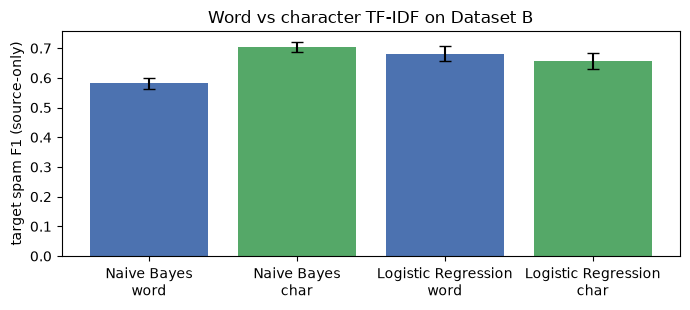

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels, vals, errs, cols = [], [], [], []
for model in ["naive_bayes", "logistic_regression"]:
    for feature, c in [("word", "#4C72B0"), ("char", "#55A868")]:
        r = summary[(summary.model == model) & (summary.feature == feature) & (summary.target_fraction == 0)].iloc[0]
        labels.append(f"{NICE[model]}\n{feature}"); vals.append(r.B_f1_mean); errs.append(r.B_f1_std); cols.append(c)
ax.bar(labels, vals, yerr=errs, capsize=4, color=cols)
ax.set_ylabel("target spam F1 (source-only)"); ax.set_title("Word vs character TF-IDF on Dataset B")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig5_word_vs_char.png", dpi=200); plt.show()

## 10. Error analysis (guide Prompt 9)

Logistic Regression with word TF-IDF, seed 42: errors of the source-only model and of the model adapted
with 40% of the pool, on the same final target test set.

The `suggested_category` column is filled by simple, visible rules (listed below) **only as a starting
point**. The guide asks students to verify every category by hand in the `manual_category` column;
the counts below are of the rule suggestions, not of verified categories.

In [23]:
b_te42 = seed_tests[MAIN_SEED].copy()
src_pred = seed_preds[MAIN_SEED][("logistic_regression", "word", 0.0)]
ada_pred = seed_preds[MAIN_SEED][("logistic_regression", "word", 0.40)]

PROMO = re.compile(r"\b(offer|cashback|discount|sale|off|deal|shop|free|bonus|reward|coupon|recharge|data|plan|order now|hurry)\b")
URLNUM = re.compile(r"https?://|www\.|bit\.ly|\b\w+\.(com|in|ly)\b|\d{4,}")

def suggest(text, label):
    words = tok(text)
    oov = np.mean([w not in vocab_A for w in words]) if words else 0
    if re.search(r"\?{4,}", text):
        return "lost characters (????)"
    if len(words) <= 3:
        return "very short / ambiguous"
    if oov >= 0.5:
        return "unfamiliar vocabulary"
    if label == 1 and PROMO.search(text):
        return "promotional language"
    if URLNUM.search(text):
        return "URL / number variation"
    if label == 0:
        return "ambiguous legitimate message"
    return "other"

def error_frame(pred, setting):
    e = b_te42.assign(predicted=pred)
    e = e[e["predicted"] != e["label"]].copy()
    e["error_type"] = np.where(e["label"] == 0, "false positive (ham → spam)", "false negative (spam → ham)")
    e["share_words_unseen_in_A"] = e["message"].map(oov_rate).round(3)
    e["suggested_category"] = [suggest(t, l) for t, l in zip(e["message"], e["label"])]
    e["manual_category"] = ""   # to be filled in by the students after reading each message
    e["setting"] = setting
    return e[["setting", "error_type", "message", "label", "predicted", "share_words_unseen_in_A",
              "suggested_category", "manual_category"]]

errors = pd.concat([error_frame(src_pred, "source-only"), error_frame(ada_pred, "adapted 40%")], ignore_index=True)
errors.to_csv(f"{OUT}/tables/error_annotation_template.csv", index=False)
print(errors.groupby(["setting", "error_type"]).size().rename("errors"))
errors.head(50)

setting      error_type                 
adapted 40%  false negative (spam → ham)     3
             false positive (ham → spam)     9
source-only  false negative (spam → ham)    96
             false positive (ham → spam)    10
Name: errors, dtype: int64


,setting,error_type,message,label,predicted,share_words_unseen_in_A,suggested_category,manual_category
0,source-only,false negative (spam → ham),"wednesday bonus at smart point store,bangalore! potato rs 23/kg,sweet corn rs 12/pc,papaya rs 23/kg,valid on 6 oct,c...",1,0,0.333,promotional language,
1,source-only,false negative (spam → ham),we know you'll love this offer! up to 80% + extra 20% off on beauty & personal care only @ beauty blowout sale | cod...,1,0,0.148,promotional language,
2,source-only,false negative (spam → ham),lenskart online mega sale: buy1get1 free + upto 40% off on eye & sunglasses! fresh stocks added.tnc shop lskt.me/meg...,1,0,0.300,promotional language,
3,source-only,false negative (spam → ham),"wednesday bonus@jiomart,bangalore!onion rs 29/kg,pear indian rs 89/kg,cabbage rs 12/pc,also at smart &smart point st...",1,0,0.286,promotional language,
4,source-only,false negative (spam → ham),"hi! the validity of your daily data pack has expired. continue to browse at 4p/10kb. to buy a data pack, click bit.l...",1,0,0.185,promotional language,
5,source-only,false negative (spam → ham),"free 2gb data for data lovers like you! now get 2gb data on airtel thanks app, download now i.airtel.in/2gb_rc2",1,0,0.143,promotional language,
6,source-only,false positive (ham → spam),guys please join handover call,0,1,0.200,ambiguous legitimate message,
7,source-only,false negative (spam → ham),monthly shopping@vishal mega mart tatatea1kg rs 151off sunflower oil 135/l colgate 500g 65off tide 5kg 115off 2kgsug...,1,0,0.682,unfamiliar vocabulary,
8,source-only,false negative (spam → ham),"hi 901969xxxx, rs.56,6oo/- bonus is credited t0 your wallet n0 xx32 0n 28 aug. directly move to your bank a/c n0w oi...",1,0,0.462,promotional language,
9,source-only,false negative (spam → ham),"data alert! 7.53mb left on data pack, post which std. charges apply or lower speeds as per plan. click bit.ly/vidata...",1,0,0.138,promotional language,


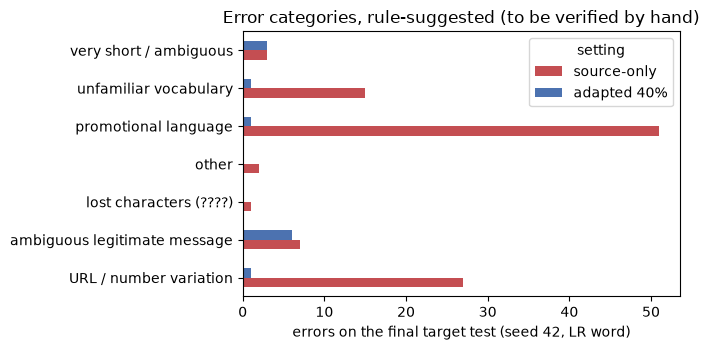

setting,source-only,adapted 40%
suggested_category,,
URL / number variation,27,1
ambiguous legitimate message,7,6
lost characters (????),1,0
other,2,0
promotional language,51,1
unfamiliar vocabulary,15,1
very short / ambiguous,3,3


In [24]:
counts = errors.groupby(["suggested_category", "setting"]).size().unstack(fill_value=0)
counts = counts.reindex(columns=["source-only", "adapted 40%"], fill_value=0)
counts.to_csv(f"{OUT}/tables/table5_error_categories_suggested.csv")
ax = counts.plot.barh(figsize=(7, 3.6), color=["#C44E52", "#4C72B0"])
ax.set_xlabel("errors on the final target test (seed 42, LR word)"); ax.set_ylabel("")
ax.set_title("Error categories, rule-suggested (to be verified by hand)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig6_error_categories.png", dpi=200); plt.show()
counts

## 11. Statistical analysis (guide Prompt 10)

* **Mean ± SD** over three seeds is in Tables 3 and 4.
* **Consistency:** does adaptation raise F1 in every seed, not only on average?
* **McNemar's test** compares two models on the *same* test messages using only the messages where
  they disagree (b = only model 1 right, c = only model 2 right). It is the right paired test here
  because both models are scored on identical messages. With three seeds we report the test per seed
  rather than claiming a general significance.

In [25]:
delta_rows = []
for seed in SEEDS:
    for model in ["naive_bayes", "logistic_regression"]:
        for feature in ["word", "char"]:
            base = runs[(runs.seed == seed) & (runs.model == model) & (runs.feature == feature) & (runs.target_fraction == 0)].B_f1.iloc[0]
            for frac in [0.10, 0.20, 0.40]:
                f = runs[(runs.seed == seed) & (runs.model == model) & (runs.feature == feature) & (runs.target_fraction == frac)].B_f1.iloc[0]
                y = seed_tests[seed]["label"].values
                p0, p1 = seed_preds[seed][(model, feature, 0.0)], seed_preds[seed][(model, feature, frac)]
                b = int(((p0 == y) & (p1 != y)).sum()); c = int(((p0 != y) & (p1 == y)).sum())
                pval = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
                delta_rows.append({"seed": seed, "model": NICE[model], "feature": feature, "fraction": f"{int(frac * 100)}%",
                                   "F1 source-only": base, "F1 adapted": f, "ΔF1": f - base,
                                   "only source-only right (b)": b, "only adapted right (c)": c, "McNemar p": pval})
deltas = pd.DataFrame(delta_rows)
deltas.to_csv(f"{OUT}/tables/table6b_delta_f1_mcnemar.csv", index=False)

consistency = deltas.groupby(["model", "feature", "fraction"]).agg(
    mean_delta_F1=("ΔF1", "mean"), sd_delta_F1=("ΔF1", "std"),
    seeds_improved=("ΔF1", lambda s: f"{int((s > 0).sum())}/{len(s)}"),
    seeds_p_below_0_05=("McNemar p", lambda s: f"{int((s < 0.05).sum())}/{len(s)}")).reset_index()
consistency.to_csv(f"{OUT}/tables/table8_consistency.csv", index=False)
consistency.round(4)

,model,feature,fraction,mean_delta_F1,sd_delta_F1,seeds_improved,seeds_p_below_0_05
0,Logistic Regression,char,10%,0.3094,0.0337,3/3,3/3
1,Logistic Regression,char,20%,0.3141,0.0316,3/3,3/3
2,Logistic Regression,char,40%,0.3211,0.0257,3/3,3/3
3,Logistic Regression,word,10%,0.2828,0.0264,3/3,3/3
4,Logistic Regression,word,20%,0.2869,0.0300,3/3,3/3
5,Logistic Regression,word,40%,0.2936,0.0294,3/3,3/3
6,Naive Bayes,char,10%,0.2388,0.0169,3/3,3/3
7,Naive Bayes,char,20%,0.2528,0.0264,3/3,3/3
8,Naive Bayes,char,40%,0.2624,0.0277,3/3,3/3
9,Naive Bayes,word,10%,0.3683,0.0207,3/3,3/3


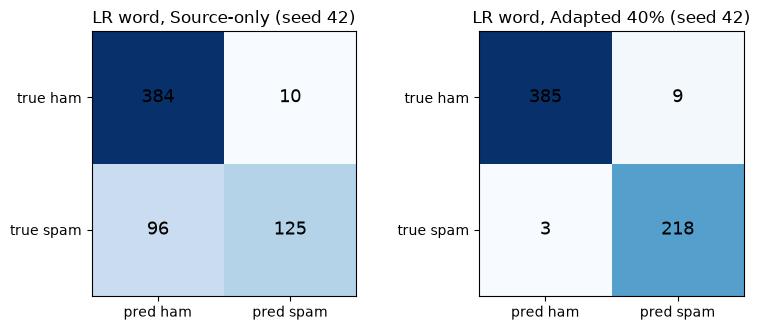

,Evaluation setting,TN,FP,FN,TP
0,"Source-only on target B, Naive Bayes",383,11,128,93
1,"Adapted (40%) on target B, Naive Bayes",390,4,2,219
2,"Source-only on target B, Logistic Regression",384,10,96,125
3,"Adapted (40%) on target B, Logistic Regression",385,9,3,218


In [26]:
# Table 6: confusion matrices on the final target test set (seed 42, word TF-IDF)
t6 = []
for model in ["naive_bayes", "logistic_regression"]:
    for frac, name in [(0.0, "Source-only on target B"), (0.40, "Adapted (40%) on target B")]:
        r = runs[(runs.seed == MAIN_SEED) & (runs.model == model) & (runs.feature == "word") & (runs.target_fraction == frac)].iloc[0]
        t6.append({"Evaluation setting": f"{name}, {NICE[model]}", "TN": r.B_TN, "FP": r.B_FP, "FN": r.B_FN, "TP": r.B_TP})
table6 = pd.DataFrame(t6)
table6.to_csv(f"{OUT}/tables/table6_confusion_matrices.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, (frac, title) in zip(axes, [(0.0, "Source-only"), (0.40, "Adapted 40%")]):
    r = runs[(runs.seed == MAIN_SEED) & (runs.model == "logistic_regression") & (runs.feature == "word") & (runs.target_fraction == frac)].iloc[0]
    cm = np.array([[r.B_TN, r.B_FP], [r.B_FN, r.B_TP]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="black")
    ax.set_xticks([0, 1], ["pred ham", "pred spam"]); ax.set_yticks([0, 1], ["true ham", "true spam"])
    ax.set_title(f"LR word, {title} (seed 42)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig7_confusion_matrices.png", dpi=200); plt.show()
table6

## 12. Save the models used by the application
Two Logistic Regression models with word TF-IDF (seed 42) are saved with joblib, together with Naive
Bayes versions: the **baseline** (Dataset A only) and the **adapted** model (Dataset A + 40% of the
target pool). The app loads these files and never retrains.

In [27]:
a_tr, _ = train_test_split(A, test_size=0.20, stratify=A["label"], random_state=MAIN_SEED)
pool, b_te = train_test_split(B, test_size=0.30, stratify=B["label"], random_state=MAIN_SEED)
add40, _ = train_test_split(pool, train_size=0.40, stratify=pool["label"], random_state=MAIN_SEED)
saved = {}
for model in ["logistic_regression", "naive_bayes"]:
    for tag, train in [("baseline", a_tr), ("adapted40", pd.concat([a_tr, add40]))]:
        pipe = make_pipeline(model, "word").fit(train["message"], train["label"])
        path = f"{OUT}/models/{model}_word_{tag}.joblib"
        joblib.dump(pipe, path)
        saved[f"{model}_word_{tag}"] = {"path": path, "train_messages": len(train), "seed": MAIN_SEED,
                                         "target_test_f1": scores(b_te["label"], pipe.predict(b_te["message"]))["f1"]}

results = {
    "seeds": SEEDS, "hyperparameters": {f"{m}|{f}": v for (m, f), v in BEST.items()}, "group_aware": t9.to_dict("records"), "nb_default_alpha": nb_default_row, "adapt_fractions": ADAPT_FRACTIONS, "features": FEATURES,
    "dataset_statistics": table1.to_dict("records"), "cleaning_steps": steps.to_dict("records"),
    "within_vs_cross": table2.to_dict("records"), "cross_domain_full_B": cross_domain.to_dict("records"),
    "domain_characteristics": char_tab.to_dict("records"),
    "adaptation_summary": summary.to_dict("records"), "consistency": consistency.to_dict("records"),
    "confusion_seed42": table6.to_dict("records"), "saved_models": saved,
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
with open(f"{OUT}/results.json", "w") as fh:
    json.dump(results, fh, indent=1, default=str)
print(json.dumps(saved, indent=1))

{
 "logistic_regression_word_baseline": {
  "path": "outputs/models/logistic_regression_word_baseline.joblib",
  "train_messages": 4126,
  "seed": 42,
  "target_test_f1": 0.702247191011236
 },
 "logistic_regression_word_adapted40": {
  "path": "outputs/models/logistic_regression_word_adapted40.joblib",
  "train_messages": 4700,
  "seed": 42,
  "target_test_f1": 0.9732142857142857
 },
 "naive_bayes_word_baseline": {
  "path": "outputs/models/naive_bayes_word_baseline.joblib",
  "train_messages": 4126,
  "seed": 42,
  "target_test_f1": 0.5723076923076923
 },
 "naive_bayes_word_adapted40": {
  "path": "outputs/models/naive_bayes_word_adapted40.joblib",
  "train_messages": 4700,
  "seed": 42,
  "target_test_f1": 0.9864864864864865
 }
}
